In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"00 placement.csv")
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package (In LPA)')

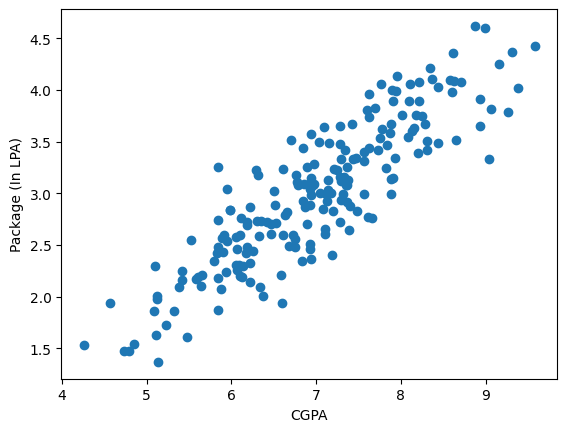

In [3]:
plt.scatter(df['cgpa'], df['package'])
plt.xlabel("CGPA")
plt.ylabel("Package (In LPA)")

In [4]:
x = df.iloc[:,0:-1]
y = df.iloc[:, -1]

print("-"*25 + "x.head"+ "-"*25)
print(x.head())

print("-"*25 + "y.head"+ "-"*25)
print(y.head())

-------------------------x.head-------------------------
   cgpa
0  6.89
1  5.12
2  7.82
3  7.42
4  6.94
-------------------------y.head-------------------------
0    3.26
1    1.98
2    3.25
3    3.67
4    3.57
Name: package, dtype: float64


In [5]:
# Train Test Split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(x_train.shape)
print(y_test.shape)

print(x_train.shape)
print(y_test.shape)

(160, 1)
(40,)
(160, 1)
(40,)


In [6]:
# Training the model

from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
y_pred = lr.predict(x_test)

y_pred[0:5]

array([2.9383335 , 4.36894346, 3.18258398, 1.89736121, 3.49662031])

Text(0, 0.5, 'Package')

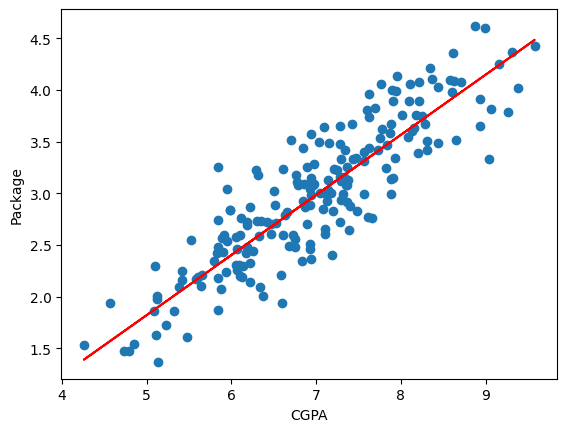

In [8]:
plt.scatter(df['cgpa'], df['package'])
plt.plot(x_train, lr.predict(x_train), color = 'red')
plt.xlabel("CGPA")
plt.ylabel("Package")


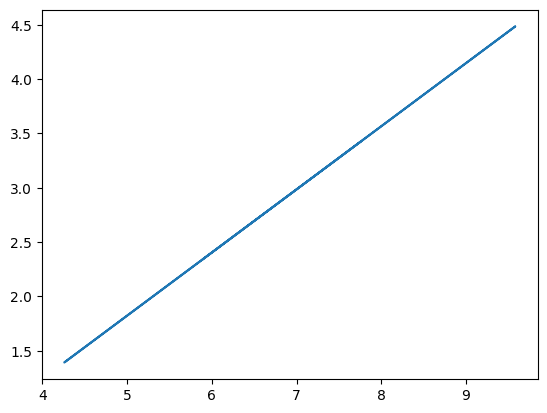

In [9]:
plt.plot(x_train, lr.predict(x_train))

In [11]:
# Let's get slopw(m) and intercept(c)

m = lr.coef_
c = lr.intercept_

print(f'''Slope (m) = {m[0]}
Intercept (c) = {c}
''')

Slope (m) = 0.581548765068508
Intercept (c) = -1.0859839580358042



In [12]:
print(x_test.iloc[0,0])
print(y_pred[0])

6.92
2.938333496238271


In [13]:
# y = mx.c

# Let's find if we are getting same value in x_test by substitutiong value of x_test in formula

m[0]*8.6+c

# See, we are getting same result which model predicted

3.9153354215533636

# Calculating Regression Metrices.
1) Mean Absolute Error (MAE)
2) Mean Squared Error (MSE)
3) Root Mean Squared Error (RMSE)
4) R2 Score
5) Adjusted R2 Score

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [19]:
y_pred = lr.predict(x_test).round(4)
y_pred

array([2.9383, 4.3689, 3.1826, 1.8974, 3.4966, 3.3512, 2.7697, 2.95  ,
       3.0721, 3.9444, 3.5722, 2.95  , 2.7581, 2.6476, 3.6711, 3.2175,
       3.9793, 2.9093, 2.194 , 3.3105, 4.2992, 2.8918, 1.8741, 2.3044,
       3.6246, 2.13  , 3.927 , 2.3684, 1.5717, 2.066 , 2.3103, 3.6885,
       3.5024, 3.0372, 2.572 , 2.3917, 3.171 , 3.8223, 3.1593, 2.9441])

In [20]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2-Score: {r2}")

MAE: 0.29931
MSE: 0.13700198649999998
RMSE: 0.37013779393625823
R2-Score: 0.7283430075859612


In [21]:
# Now lets find Adjusted r2 score

print(x_test.shape)

(40, 1)


In [24]:
ar2 = 1 - ((1-r2)*(40-1)) / (40-1-1)
print(f"AR2-Score: {ar2}")

AR2-Score: 0.7211941393645391


# Now, let's add an irrelevant feature. You will notice that `R2 score` increased or remain same, whereas `Adjusted R2` score decreased

In [31]:
random_feature = np.random.random(200)   
# Returns 200 values between 0 and 1
# 200 bcz we have total 200 rows in our dataset

df2 = df.copy()
df2['random_feature'] = random_feature
df2 = df2[['cgpa', 'random_feature', 'package']]

df2

,cgpa,random_feature,package
0,6.89,0.552447,3.26
1,5.12,0.903507,1.98
2,7.82,0.066190,3.25
3,7.42,0.500049,3.67
4,6.94,0.125671,3.57
...,...,...,...
195,6.93,0.901318,2.46
196,5.89,0.020100,2.57
197,7.21,0.110726,3.24
198,7.63,0.086538,3.96


In [32]:
x = df2.iloc[:,0:-1]
y = df2.iloc[:, -1]

print("-"*25 + "x.head"+ "-"*25)
print(x.head())

print("-"*25 + "y.head"+ "-"*25)
print(y.head())

-------------------------x.head-------------------------
   cgpa  random_feature
0  6.89        0.552447
1  5.12        0.903507
2  7.82        0.066190
3  7.42        0.500049
4  6.94        0.125671
-------------------------y.head-------------------------
0    3.26
1    1.98
2    3.25
3    3.67
4    3.57
Name: package, dtype: float64


In [33]:
# Train Test Split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(x_train.shape)
print(y_test.shape)

print(x_train.shape)
print(y_test.shape)

(160, 2)
(40,)
(160, 2)
(40,)


In [34]:
# Training the model

from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
y_pred = lr.predict(x_test).round(4)
y_pred

array([2.9386, 4.3621, 3.1786, 1.8949, 3.4951, 3.3564, 2.7687, 2.9544,
       3.0773, 3.9395, 3.5701, 2.9426, 2.7562, 2.6492, 3.6671, 3.2121,
       3.9831, 2.9086, 2.1974, 3.3049, 4.2997, 2.8883, 1.8662, 2.2992,
       3.6185, 2.1259, 3.928 , 2.3617, 1.5651, 2.0685, 2.3049, 3.682 ,
       3.5085, 3.043 , 2.565 , 2.3945, 3.1696, 3.8173, 3.1534, 2.9479])

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2-Score: {r2}")

# See R2 score is same. Not changed

MAE: 0.2990325
MSE: 0.13682007775
RMSE: 0.36989198119180683
R2-Score: 0.7287037088077554


In [38]:
x_test.shape

(40, 2)

In [40]:
ar2 = 1 - ((1-r2)*(40-1)) / (40-2-1)
print(f"AR2-Score: {ar2}")

# See, earlier Adjusted R2 score was 0.72 and here it is 0.71. So it compensated because we added an irrelevant column.

AR2-Score: 0.7140390444189854


In [41]:
lr.coef_

array([ 0.58181731, -0.01375766])

## Linear Regression Coefficients Interpretation

```python
lr.coef_ = [0.58181731, -0.01375766]
````

**Feature order:**

```python
['cgpa', 'random_feature']
```

---

## Interpretation

### 1. CGPA Coefficient

**0.5818**

* If **CGPA increases by 1 unit**, the **package increases by ~0.58 LPA**
* This shows a **strong and meaningful relationship**

---

### 2. Random Feature Coefficient

**-0.0137**

* If **random_feature increases by 1 unit**, the **package decreases by ~0.013 LPA**
* This effect is **very small → almost negligible**

---

## Model Equation

```
package = 0.5818 * cgpa - 0.0137 * random_feature + intercept
```

---

## Key Insight

* **CGPA → Important feature**
* **Random Feature → Useless (noise)**
